# Baseline: Faster R-CNN v2 (ResNet-50 + FPN) sobre *pills-sxdht*

Este cuaderno establece el **rendimiento base (baseline)** del detector *two-stage* **Faster R-CNN v2**, preentrenado en MS COCO, sobre el dataset **pills-sxdht** de Roboflow-100 (pastillas identificadas por marca o por color).

**Qué entendemos por baseline:** un *fine-tuning* lo más sencillo posible, que sirva de punto de referencia para las mejoras posteriores. Por eso, deliberadamente:

| Aspecto | Configuración del baseline |
|---|---|
| Pesos iniciales | `COCO_V1` de torchvision |
| Capas entrenables del backbone | las de por defecto de torchvision (3 últimas etapas de la ResNet-50) |
| Cabeza de clasificación | nueva, con 7 clases + fondo |
| Aumento de datos | **ninguno** |
| Optimizador | SGD (lr 0.005, momentum 0.9, weight decay 5e-4) |
| Política de *learning rate* | **constante**, sin *scheduler* |
| Resolución | la de por defecto del modelo (redimensiona internamente a 800 px de lado corto) |
| Post-procesado | umbrales de por defecto de torchvision (score ≥ 0.05, NMS IoU 0.5, 100 detecciones por imagen) |

Todo lo que aparece en la tabla es candidato a convertirse en una **estrategia de mejora**, que se comparará contra los números obtenidos aquí.

**Estructura del cuaderno**

1. Configuración y reproducibilidad
2. Carga del dataset
3. Análisis exploratorio del dataset
4. Limpieza de clases
5. Modelo
6. Dataset de PyTorch y DataLoaders
7. Funciones de entrenamiento y evaluación
8. Entrenamiento
9. Curvas de entrenamiento
10. Evaluación en test: mAP y curvas PR
11. Tiempo de inferencia
12. Análisis cualitativo
13. Análisis de errores (TIDE)
14. Resumen del baseline

## 1. Configuración y reproducibilidad

Todos los hiperparámetros del baseline están en esta celda, para que cualquier experimento de mejora se pueda definir cambiando solo estos valores.

Se fijan las semillas de `random`, `numpy` y `torch`. En CPU los resultados son reproducibles; en GPU puede quedar una pequeña variación porque algunas operaciones de torchvision (como `roi_align` en el *backward*) no son deterministas.

In [2]:
# Dependencias que pueden no estar instaladas
try:
    import datasets, torchmetrics, pycocotools  # noqa: F401
except ImportError:
    %pip install -q datasets torchmetrics pycocotools

import copy
import json
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

%matplotlib inline

# ---------------- Hiperparámetros del baseline ----------------
SEED = 42
NUM_EPOCHS = 15
BATCH_SIZE = 4
LR = 0.005
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

OUT_DIR = Path("resultados/baseline_fasterrcnn")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))

Dispositivo: cpu


## 2. Carga del dataset

Se usan las particiones `train` / `validation` / `test` que proporciona Hugging Face, tal y como pide el guion. Las anotaciones vienen en formato COCO: cada caja es `[x, y, ancho, alto]` en píxeles.

In [3]:
from datasets import load_dataset

DATASET = "Francesco/pills-sxdht"
train_dataset = load_dataset(DATASET, split="train")
valid_dataset = load_dataset(DATASET, split="validation")
test_dataset  = load_dataset(DATASET, split="test")

print(train_dataset)
print(f"Imágenes -> train: {len(train_dataset)} | valid: {len(valid_dataset)} | test: {len(test_dataset)}")

Dataset({
    features: ['image_id', 'image', 'width', 'height', 'objects'],
    num_rows: 316
})
Imágenes -> train: 316 | valid: 45 | test: 90


## 3. Análisis exploratorio del dataset

Antes de entrenar revisamos tres cosas que condicionan el comportamiento del detector:

- **Distribución de clases**: si hay clases con muy pocos ejemplos.
- **Tamaño de los objetos**: con los umbrales de COCO (pequeño < 32², mediano < 96², grande ≥ 96² píxeles de área).
- **Objetos por imagen**: densidad de las escenas.

In [4]:
all_names = train_dataset.features["objects"]["category"].feature.names
splits = {"train": train_dataset, "valid": valid_dataset, "test": test_dataset}


def size_bucket(w, h):
    area = w * h
    return "pequeño" if area < 32**2 else ("mediano" if area < 96**2 else "grande")


stats = {}
for name, ds in splits.items():
    objs = ds["objects"]  # solo la columna de anotaciones: no decodifica imágenes
    cats = Counter(c for o in objs for c in o["category"])
    sizes = Counter(size_bucket(b[2], b[3]) for o in objs for b in o["bbox"])
    per_img = [len(o["category"]) for o in objs]
    stats[name] = dict(cats=cats, sizes=sizes, per_img=per_img)

print("Tamaño de imagen:", Counter(zip(train_dataset["width"], train_dataset["height"])).most_common(3))
print()
print(f"{'id':>2}  {'clase':<22}{'train':>7}{'valid':>7}{'test':>7}")
for i, n in enumerate(all_names):
    print(f"{i:>2}  {n:<22}" + "".join(f"{stats[s]['cats'][i]:>7}" for s in splits))
print()
for s in splits:
    tot = sum(stats[s]["sizes"].values())
    pct = {k: f"{100 * v / tot:.0f}%" for k, v in stats[s]["sizes"].items()}
    pi = stats[s]["per_img"]
    print(f"{s:<6} cajas: {tot:4d} | tamaños: {pct} | objetos/imagen: media {np.mean(pi):.1f}, máx {max(pi)}")

Tamaño de imagen: [((640, 640), 316)]

id  clase                   train  valid   test
 0  pills                       0      0      0
 1  Cipro 500                  79      8     26
 2  Ibuphil 600 mg              1      0      1
 3  Ibuphil Cold 400-60        55      7     10
 4  Xyzall 5mg                 57      5     10
 5  blue                       42      6     11
 6  pink                       35      8     15
 7  red                        40      5     15
 8  white                      42      8     10

train  cajas:  351 | tamaños: {'grande': '65%', 'mediano': '34%', 'pequeño': '1%'} | objetos/imagen: media 1.1, máx 4
valid  cajas:   47 | tamaños: {'grande': '68%', 'mediano': '32%'} | objetos/imagen: media 1.0, máx 3
test   cajas:   98 | tamaños: {'grande': '76%', 'mediano': '22%', 'pequeño': '2%'} | objetos/imagen: media 1.1, máx 5


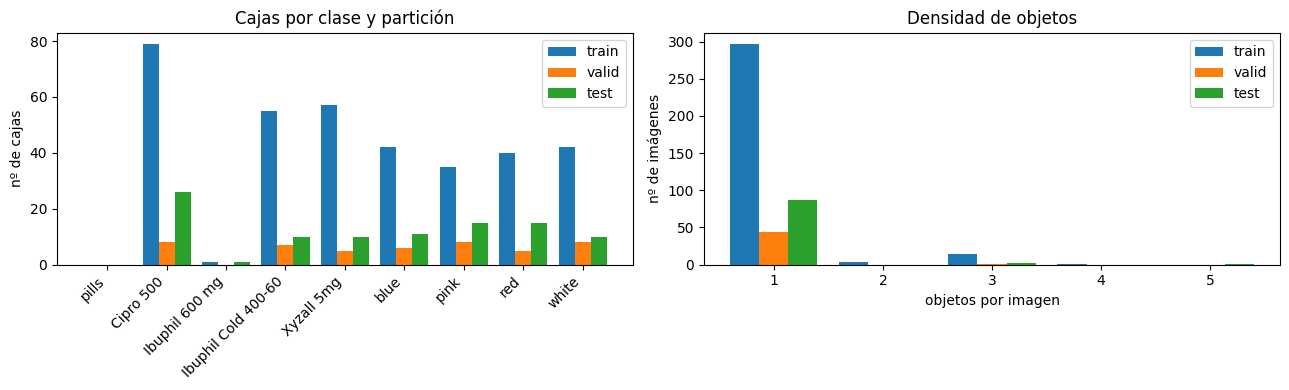

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

x = np.arange(len(all_names))
for k, s in enumerate(splits):
    axes[0].bar(x + (k - 1) * 0.27, [stats[s]["cats"][i] for i in x], width=0.27, label=s)
axes[0].set_xticks(x, all_names, rotation=45, ha="right")
axes[0].set_ylabel("nº de cajas")
axes[0].set_title("Cajas por clase y partición")
axes[0].legend()

bins = np.arange(1, max(max(stats[s]["per_img"]) for s in splits) + 2) - 0.5
axes[1].hist([stats[s]["per_img"] for s in splits], bins=bins, label=list(splits))
axes[1].set_xlabel("objetos por imagen")
axes[1].set_ylabel("nº de imágenes")
axes[1].set_title("Densidad de objetos")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUT_DIR / "eda.png", dpi=120)
plt.show()

## 4. Limpieza de clases

El `ClassLabel` del dataset tiene 9 nombres, pero el guion habla de 7 clases. La tabla anterior explica la diferencia:

- **`pills` (id 0)**: es la supercategoría que exporta Roboflow; no tiene ninguna anotación.
- **`Ibuphil 600 mg` (id 2)**: solo aparece una vez en train y otra en test, así que el modelo no puede aprenderla.

Ambas se descartan. Las imágenes que contienen `Ibuphil 600 mg` **se eliminan completas**: si solo se borrara su caja, la pastilla seguiría visible sin anotar y el modelo aprendería a considerarla fondo.

Las etiquetas se reasignan a 1..7, porque en torchvision la etiqueta 0 está reservada para el fondo.

In [6]:
KEEP_IDS = [1, 3, 4, 5, 6, 7, 8]
DROP_IDS = {0, 2}

# id original del dataset -> etiqueta del modelo (1..7)
ID2LABEL = {orig: new for new, orig in enumerate(KEEP_IDS, start=1)}
CLASSES = ["__background__"] + [all_names[i] for i in KEEP_IDS]
NUM_CLASSES = len(CLASSES)  # 7 clases + fondo = 8

for orig, new in ID2LABEL.items():
    print(f"  {orig} -> {new}  {all_names[orig]}")

  1 -> 1  Cipro 500
  3 -> 2  Ibuphil Cold 400-60
  4 -> 3  Xyzall 5mg
  5 -> 4  blue
  6 -> 5  pink
  7 -> 6  red
  8 -> 7  white


## 5. Modelo

Se carga Faster R-CNN v2 con los pesos `COCO_V1` y se sustituye el **predictor de la cabeza ROI** (clasificación + regresión de cajas) por uno nuevo con `NUM_CLASSES` salidas. El resto de la red (backbone, FPN, RPN y capas convolucionales de la cabeza) conserva los pesos de COCO.

Por defecto torchvision deja congeladas la primera convolución y la primera etapa de la ResNet-50, y entrena el resto. Esto se mantiene en el baseline.

In [7]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

set_seed(SEED)  # la inicialización de la nueva cabeza también debe ser reproducible

model = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
model.to(device)

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros: {n_total / 1e6:.1f} M totales | {n_train / 1e6:.1f} M entrenables")
print("Redimensionado interno:", model.transform)

Parámetros: 43.3 M totales | 43.1 M entrenables
Redimensionado interno: GeneralizedRCNNTransform(
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    Resize(min_size=(800,), max_size=1333, mode='bilinear')
)


## 6. Dataset de PyTorch y DataLoaders

`PillsDataset` adapta cada ejemplo de Hugging Face al formato que espera torchvision:

- **imagen**: tensor `float32` en [0, 1]. La normalización y el redimensionado los hace el propio modelo (`GeneralizedRCNNTransform`), así que no se aplican aquí.
- **target**: diccionario con `boxes` en formato `[x1, y1, x2, y2]` y `labels` con las etiquetas 1..7.

En el baseline **no hay aumento de datos**: train, validación y test usan la misma transformación.

Como cada imagen tiene un número distinto de cajas, `collate_fn` devuelve listas en lugar de apilar tensores.

In [8]:
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2


class PillsDataset(Dataset):
    # Adapta el dataset de Hugging Face al formato de los detectores de torchvision

    def __init__(self, hf_ds, transforms=None):
        # Se descartan las imágenes con clases eliminadas (ver sección 4)
        self.ds = hf_ds.filter(lambda o: not any(c in DROP_IDS for c in o["category"]),
                               input_columns="objects")
        self.transforms = transforms

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        item = self.ds[idx]
        img = item["image"].convert("RGB")
        objs = item["objects"]

        # COCO [x, y, w, h] -> [x1, y1, x2, y2]
        boxes = torch.tensor(objs["bbox"], dtype=torch.float32).reshape(-1, 4)
        boxes[:, 2:] += boxes[:, :2]

        target = {
            "boxes": tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=(img.height, img.width)),
            "labels": torch.tensor([ID2LABEL[c] for c in objs["category"]], dtype=torch.int64),
            "image_id": item["image_id"],
        }
        if self.transforms is not None:
            img, target = self.transforms(img, target)
        return img, target


# Baseline: sin aumento de datos, misma transformación para todas las particiones
base_tf = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

train_ds = PillsDataset(train_dataset, base_tf)
valid_ds = PillsDataset(valid_dataset, base_tf)
test_ds  = PillsDataset(test_dataset,  base_tf)
print(f"Imágenes tras la limpieza -> train: {len(train_ds)} | valid: {len(valid_ds)} | test: {len(test_ds)}")


def collate_fn(batch):
    return tuple(zip(*batch))


# Generador con semilla: el orden aleatorio de train es el mismo en cada ejecución
g = torch.Generator().manual_seed(SEED)

# num_workers=0: en Windows + Jupyter los workers no pueden importar clases definidas en el cuaderno
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate_fn, num_workers=0, generator=g)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=0)

images, targets = next(iter(train_loader))
print("Ejemplo:", images[0].shape, images[0].dtype, "| cajas:", targets[0]["boxes"].shape[0],
      "| etiquetas:", targets[0]["labels"].tolist())

Imágenes tras la limpieza -> train: 315 | valid: 45 | test: 89
Ejemplo: torch.Size([3, 640, 640]) torch.float32 | cajas: 1 | etiquetas: [6]


## 7. Funciones de entrenamiento y evaluación

- **`train_one_epoch`**: en modo `train` el modelo devuelve un diccionario con 4 pérdidas (clasificación y regresión de la RPN, y clasificación y regresión de la cabeza ROI). Se suman y se optimiza la suma.
- **`validation_loss`**: calcula esas mismas pérdidas sobre validación para comparar las curvas de train y validación. Para obtener las pérdidas hay que poner el modelo en modo `train`, pero las capas **BatchNorm** (presentes en la FPN y las cabezas de la versión v2) se dejan en modo `eval` para no modificar sus estadísticas con datos de validación.
- **`evaluate`**: obtiene las predicciones en modo `eval` y calcula el mAP con `torchmetrics`, que usa `pycocotools` por debajo (las mismas métricas oficiales de COCO).

In [9]:
from torchmetrics.detection import MeanAveragePrecision


def to_device(images, targets):
    images = [img.to(device) for img in images]
    targets = [{k: (v.to(device) if torch.is_tensor(v) else v) for k, v in t.items()} for t in targets]
    return images, targets


def train_one_epoch(model, loader, optimizer):
    model.train()
    total, n = 0.0, 0
    for images, targets in loader:
        images, targets = to_device(images, targets)
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item() * len(images)
        n += len(images)
    return total / n


@torch.no_grad()
def validation_loss(model, loader):
    model.train()
    for m in model.modules():
        if isinstance(m, torch.nn.BatchNorm2d):
            m.eval()
    total, n = 0.0, 0
    for images, targets in loader:
        images, targets = to_device(images, targets)
        loss = sum(model(images, targets).values())
        total += loss.item() * len(images)
        n += len(images)
    model.eval()
    return total / n


@torch.no_grad()
def evaluate(model, loader, extended=False):
    # extended=True añade AP por clase y la matriz de precisión para las curvas PR
    model.eval()
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox",
                                  class_metrics=extended, extended_summary=extended)
    for images, targets in loader:
        images, targets = to_device(images, targets)
        preds = model(images)
        metric.update(
            [{k: v.cpu() for k, v in p.items()} for p in preds],
            [{"boxes": t["boxes"].cpu(), "labels": t["labels"].cpu()} for t in targets],
        )
    return metric.compute()

## 8. Entrenamiento

En cada época se registra la pérdida de train y validación, y el mAP@0.5:0.95 y mAP@0.5 en validación. Se guarda el modelo de la época con **mayor mAP@0.5:0.95 en validación** (`best_model.pth`). El conjunto de test no se usa en ningún momento para tomar decisiones.

> En CPU cada época tarda bastante (Faster R-CNN trabaja a 800 px). Para una primera prueba rápida se puede bajar `NUM_EPOCHS` en la sección 1.

In [9]:
set_seed(SEED)
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

history = {"train_loss": [], "val_loss": [], "val_map": [], "val_map50": []}
best_map, best_epoch, best_state = -1.0, 0, None
t_start = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer)
    val_loss = validation_loss(model, valid_loader)
    m = evaluate(model, valid_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_map"].append(m["map"].item())
    history["val_map50"].append(m["map_50"].item())

    if m["map"].item() > best_map:
        best_map, best_epoch = m["map"].item(), epoch
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, OUT_DIR / "best_model.pth")

    print(f"Época {epoch:2d}/{NUM_EPOCHS} | loss train {train_loss:.4f} | loss val {val_loss:.4f} | "
          f"val mAP {m['map']:.4f} | val mAP@50 {m['map_50']:.4f} | {time.time() - t0:.0f}s")

train_time = time.time() - t_start
model.load_state_dict(best_state)
with open(OUT_DIR / "history.json", "w") as f:
    json.dump(history, f, indent=2)
print(f"\nMejor época: {best_epoch} (val mAP {best_map:.4f}) | tiempo total: {train_time / 60:.1f} min")

Época  1/15 | loss train 0.3802 | loss val 0.2375 | val mAP 0.3192 | val mAP@50 0.5608 | 138s
Época  2/15 | loss train 0.1766 | loss val 0.1151 | val mAP 0.6715 | val mAP@50 0.8673 | 136s
Época  3/15 | loss train 0.1030 | loss val 0.0821 | val mAP 0.7147 | val mAP@50 0.9953 | 137s
Época  4/15 | loss train 0.0741 | loss val 0.0595 | val mAP 0.7637 | val mAP@50 0.9915 | 136s
Época  5/15 | loss train 0.0573 | loss val 0.0504 | val mAP 0.8123 | val mAP@50 0.9796 | 136s
Época  6/15 | loss train 0.0493 | loss val 0.0557 | val mAP 0.8032 | val mAP@50 0.9738 | 136s
Época  7/15 | loss train 0.0455 | loss val 0.0449 | val mAP 0.8278 | val mAP@50 0.9756 | 136s
Época  8/15 | loss train 0.0429 | loss val 0.0499 | val mAP 0.8249 | val mAP@50 0.9664 | 136s
Época  9/15 | loss train 0.0367 | loss val 0.0397 | val mAP 0.8469 | val mAP@50 0.9959 | 136s
Época 10/15 | loss train 0.0319 | loss val 0.0396 | val mAP 0.8477 | val mAP@50 1.0000 | 136s
Época 11/15 | loss train 0.0309 | loss val 0.0350 | val mAP 

## 9. Curvas de entrenamiento

- Si la pérdida de validación deja de bajar (o sube) mientras la de train sigue bajando, el modelo está **sobreajustando**, algo probable con solo 315 imágenes de entrenamiento.
- El mAP en validación indica en qué época se alcanza el mejor modelo (línea discontinua).

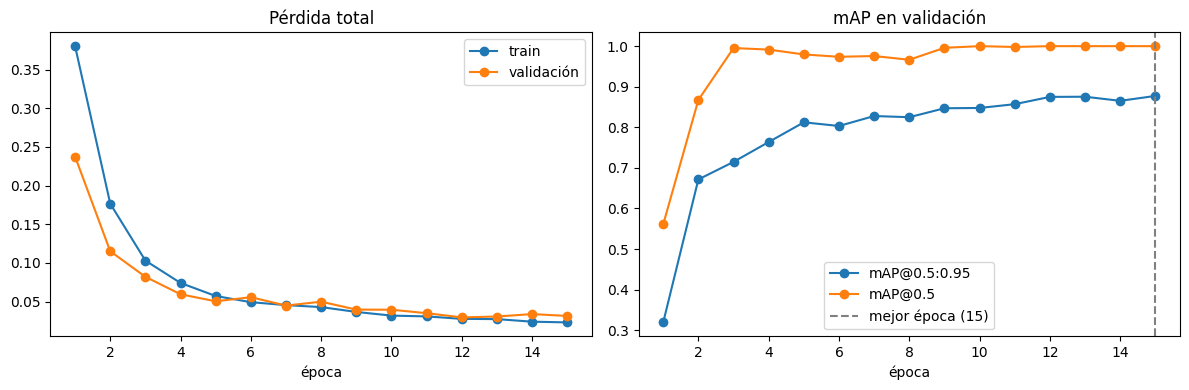

In [10]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], "o-", label="train")
axes[0].plot(epochs, history["val_loss"], "o-", label="validación")
axes[0].set_title("Pérdida total")
axes[0].set_xlabel("época")
axes[0].legend()

axes[1].plot(epochs, history["val_map"], "o-", label="mAP@0.5:0.95")
axes[1].plot(epochs, history["val_map50"], "o-", label="mAP@0.5")
axes[1].axvline(best_epoch, ls="--", c="gray", label=f"mejor época ({best_epoch})")
axes[1].set_title("mAP en validación")
axes[1].set_xlabel("época")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUT_DIR / "curvas_entrenamiento.png", dpi=120)
plt.show()

## 10. Evaluación en test: mAP y curvas PR

Estas son las **métricas del baseline**, calculadas sobre test con el mejor modelo de validación:

- **mAP@0.5:0.95**: métrica principal de COCO, media sobre umbrales de IoU de 0.5 a 0.95. Premia la precisión en la localización.
- **mAP@0.5** y **mAP@0.75**: con un único umbral de IoU.
- **mAP por tamaño** (pequeño / mediano / grande): -1 indica que no hay objetos de ese tamaño en test.
- **AP por clase**: para detectar qué clases fallan.

La matriz `precision` de pycocotools tiene forma `[IoU (10), recall (101), clase, área (4), máx. detecciones (3)]`. De ella se sacan las curvas PR por clase (área = todas, 100 detecciones por imagen).

In [11]:
res = evaluate(model, test_loader, extended=True)

precision = res["precision"]  # [T, R, K, A, M]; -1 = sin objetos de esa clase
class_ids = res["classes"].tolist()
recall_thr = np.linspace(0, 1, 101)


def ap_from_precision(p):
    p = p[p > -1]
    return p.mean().item() if p.numel() else float("nan")


per_class = {}
for k, c in enumerate(class_ids):
    per_class[CLASSES[c]] = {
        "AP": ap_from_precision(precision[:, :, k, 0, -1]),
        "AP50": ap_from_precision(precision[0, :, k, 0, -1]),
    }

print(f"mAP@0.5:0.95 : {res['map']:.4f}")
print(f"mAP@0.5      : {res['map_50']:.4f}")
print(f"mAP@0.75     : {res['map_75']:.4f}")
print(f"mAP pequeño / mediano / grande : {res['map_small']:.4f} / {res['map_medium']:.4f} / {res['map_large']:.4f}")
print(f"mAR@100      : {res['mar_100']:.4f}")
print(f"\n{'clase':<22}{'AP50:95':>9}{'AP50':>9}")
for name, v in per_class.items():
    print(f"{name:<22}{v['AP']:>9.4f}{v['AP50']:>9.4f}")

mAP@0.5:0.95 : 0.8396
mAP@0.5      : 0.9641
mAP@0.75     : 0.9641
mAP pequeño / mediano / grande : 0.3500 / 0.8583 / 0.8228
mAR@100      : 0.8818

clase                   AP50:95     AP50
Cipro 500                0.7882   0.8795
Ibuphil Cold 400-60      0.8724   1.0000
Xyzall 5mg               0.7524   0.8977
blue                     0.8950   1.0000
pink                     0.8900   1.0000
red                      0.8562   1.0000
white                    0.8226   0.9717


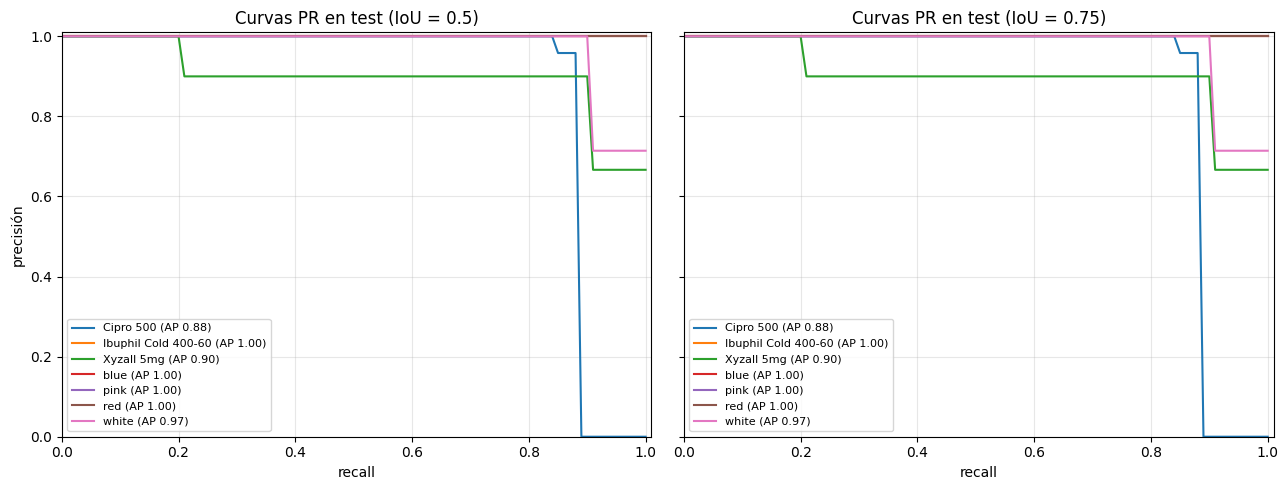

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (t_idx, iou_txt) in zip(axes, [(0, "0.5"), (5, "0.75")]):
    for k, c in enumerate(class_ids):
        p = precision[t_idx, :, k, 0, -1].numpy()
        if (p > -1).any():
            ap = ap_from_precision(precision[t_idx, :, k, 0, -1])
            ax.plot(recall_thr, np.clip(p, 0, None), label=f"{CLASSES[c]} (AP {ap:.2f})")
    ax.set_title(f"Curvas PR en test (IoU = {iou_txt})")
    ax.set_xlabel("recall")
    ax.set_xlim(0, 1.01)
    ax.set_ylim(0, 1.01)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_ylabel("precisión")
plt.tight_layout()
plt.savefig(OUT_DIR / "curvas_pr_test.png", dpi=120)
plt.show()

## 11. Tiempo de inferencia

Se mide el tiempo de una pasada del modelo por imagen (*batch* de 1), incluyendo el preprocesado interno (normalización y redimensionado) y el post-procesado (NMS). No se incluye la carga de la imagen desde disco.

Se descartan unas imágenes de calentamiento y, en GPU, se sincroniza antes de parar el cronómetro. Los tiempos solo son comparables entre modelos medidos **en el mismo hardware**.

In [13]:
@torch.no_grad()
def measure_inference(model, dataset, n_warmup=5):
    model.eval()
    imgs = [dataset[i][0] for i in range(len(dataset))]  # imágenes ya cargadas: no se mide la E/S
    for img in imgs[:n_warmup]:
        model([img.to(device)])
    times = []
    for img in imgs:
        x = img.to(device)
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        model([x])
        if device.type == "cuda":
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return np.array(times) * 1000  # ms


times_ms = measure_inference(model, test_ds)
hw = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print(f"Hardware: {hw}")
print(f"Inferencia: {times_ms.mean():.1f} ± {times_ms.std():.1f} ms/imagen "
      f"(mediana {np.median(times_ms):.1f} ms) -> {1000 / times_ms.mean():.1f} FPS")

Hardware: Tesla T4
Inferencia: 131.5 ± 1.8 ms/imagen (mediana 131.1 ms) -> 7.6 FPS


## 12. Análisis cualitativo

Se muestran algunas imágenes de test con las cajas reales (**verde**) y las predicciones del modelo con score ≥ 0.5 (**rojo**, con clase y confianza). Sirve para ver de un vistazo qué tipo de errores comete el baseline: confusiones entre clases parecidas (por ejemplo, pastillas del mismo color), cajas mal ajustadas, objetos no detectados o detecciones duplicadas.

/usr/local/lib/python3.13/dist-packages/torchvision/utils.py:375: UserWarning: Argument 'font_size' will be ignored since 'font' is not set.
  warnings.warn("Argument 'font_size' will be ignored since 'font' is not set.")


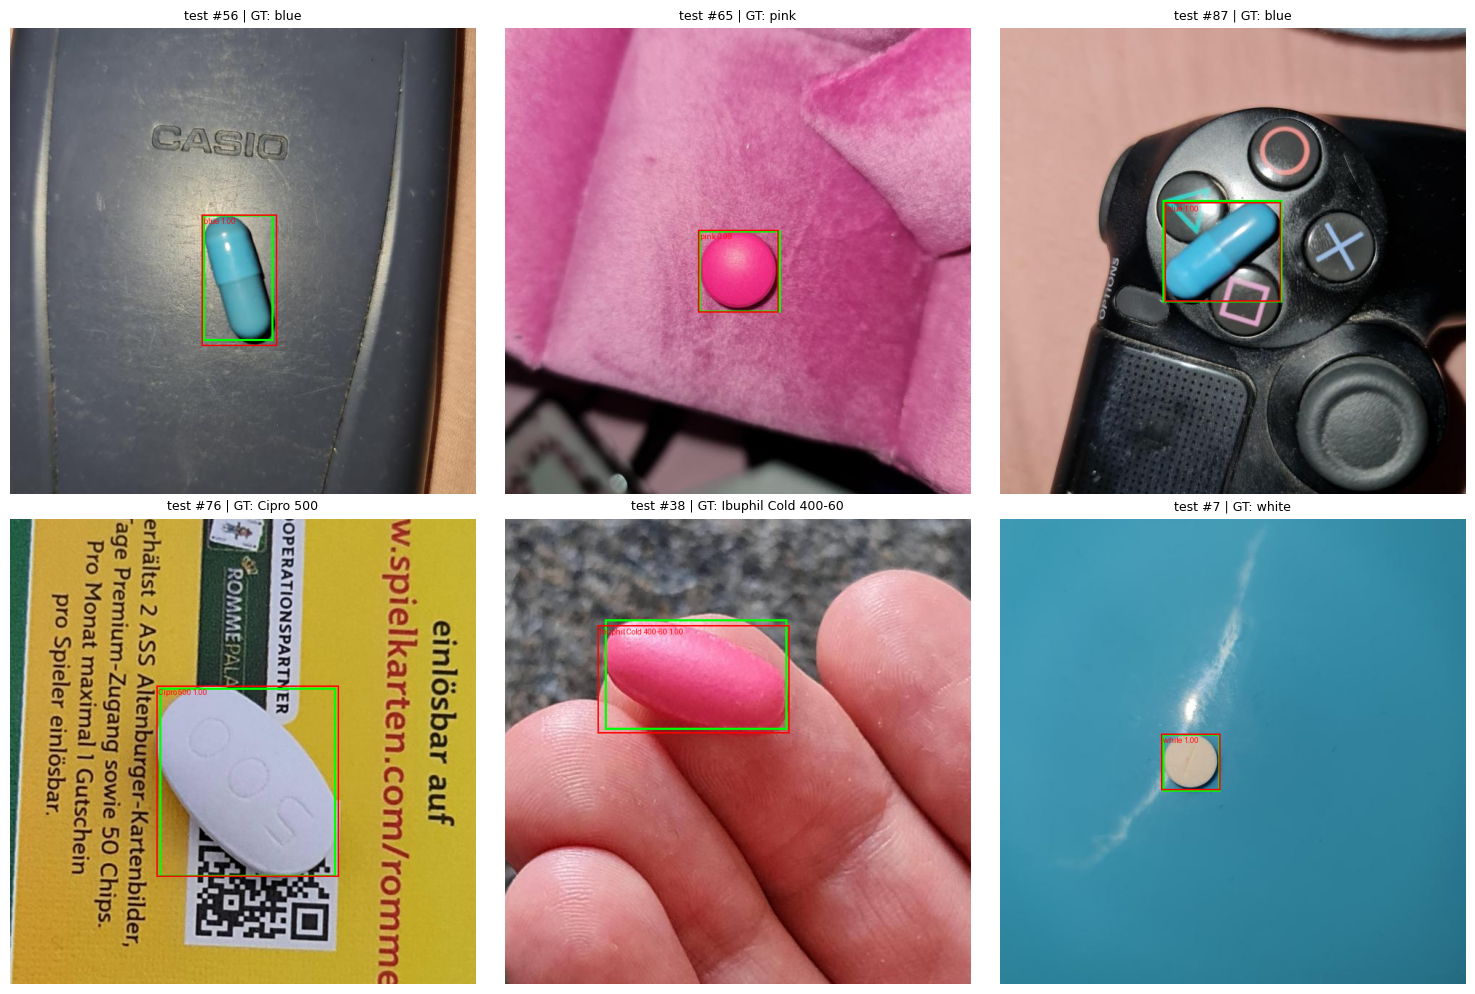

In [14]:
from torchvision.utils import draw_bounding_boxes

SCORE_THR = 0.5
N_SHOW = 6
rng = np.random.default_rng(SEED)
idxs = rng.choice(len(test_ds), size=min(N_SHOW, len(test_ds)), replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
model.eval()
for ax, i in zip(axes.flat, idxs):
    img, tgt = test_ds[int(i)]
    with torch.no_grad():
        pred = model([img.to(device)])[0]
    keep = pred["scores"] >= SCORE_THR

    canvas = (img * 255).to(torch.uint8)
    canvas = draw_bounding_boxes(canvas, tgt["boxes"], colors="lime", width=3)
    canvas = draw_bounding_boxes(
        canvas, pred["boxes"][keep].cpu(), colors="red", width=2, font_size=14,
        labels=[f"{CLASSES[l]} {s:.2f}" for l, s in zip(pred["labels"][keep].tolist(), pred["scores"][keep].tolist())],
    )
    ax.imshow(canvas.permute(1, 2, 0))
    gt_txt = ", ".join(CLASSES[l] for l in tgt["labels"].tolist())
    ax.set_title(f"test #{i} | GT: {gt_txt}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUT_DIR / "ejemplos_test.png", dpi=110)
plt.show()

## 13. Análisis de errores (TIDE)

Las métricas de la sección 10 dicen **cuánto** mAP se pierde, pero no **por qué**. Para decidir qué mejoras probar se descompone la pérdida por tipo de error con el método **TIDE** (Bolya et al., 2020), usando la implementación de `mapviz.py` vista en clase (práctica P1).

TIDE etiqueta cada detección que no es un acierto (TP) con un tipo de error:

| Error | Significado | Mejoras que apunta |
|---|---|---|
| `cls` (clasificación) | caja bien colocada (IoU ≥ umbral) pero clase equivocada | separar mejor clases parecidas: más épocas, *class-balanced loss*, más resolución para ver grabados |
| `loc` (localización) | clase correcta, la caja se solapa con el objeto pero no lo suficiente (0.1 ≤ IoU < umbral) | ajustar mejor las cajas: más peso a la pérdida de regresión, GIoU, TTA con media de cajas, más épocas con LR decreciente |
| `dup` (duplicado) | caja correcta pero el objeto ya tenía otra detección mejor | umbral de NMS |
| `bg` (fondo) | detección donde no hay ninguna pastilla | aumento de datos con fondos variados, umbral de confianza |
| `miss` (no detectado) | pastilla real que ninguna detección encuentra ni explica | más recall: anclas, resolución, aumento de datos |

Para cada tipo, TIDE calcula **cuánto AP se recuperaría si un oráculo corrigiera solo ese tipo de error**. El tipo con mayor ganancia es donde más margen de mejora hay.

**Dos umbrales de IoU.** En la sección 10, mAP@0.5 = mAP@0.75 = 0.964 y mAP@0.5:0.95 = 0.840. Eso significa que el mAP se pierde en dos tramos:

- **≈ 3.6 puntos con IoU 0.5**: errores que no dependen de la precisión de la caja (clase equivocada, fondo, no detectados). Se analizan con TIDE a **IoU 0.5**.
- **≈ 12.5 puntos con IoU ≥ 0.8**: cajas que no coinciden casi al píxel con la anotación. Con umbral 0.5 TIDE no los ve (ahí cualquier IoU ≥ 0.5 es un acierto), así que se repite el análisis a **IoU 0.85**, en mitad del tramo donde se pierde el mAP.

**Validación y test.** El análisis se hace sobre las dos particiones. Las decisiones de mejora deberían tomarse con **validación**, para que test siga siendo una evaluación independiente. Pero la validación tiene solo 45 imágenes y mAP@0.5 = 1.0, así que a IoU 0.5 no tiene errores que analizar. El análisis de test a IoU 0.5 se incluye como diagnóstico, y hay que indicarlo como limitación al presentar.

### 13.1 Predicciones en el formato de `mapviz`

`mapviz` trabaja con listas de diccionarios: una caja real es `dict(img, cls, box)` y una predicción `dict(img, cls, box, score)`, con cajas `(x1, y1, x2, y2)` en píxeles. Se guardan **todas** las detecciones que devuelve el modelo (score ≥ 0.05), igual que en el cálculo del mAP.

Si `mapviz.py` no está junto al cuaderno (por ejemplo, en Colab), se descarga del repositorio del grupo.

In [10]:
import sys
import urllib.request

if not Path("mapviz.py").exists():
    url = "https://raw.githubusercontent.com/HectorBarro/P6_CV1/main/mapviz.py"
    try:
        urllib.request.urlretrieve(url, "mapviz.py")
    except Exception as e:
        raise FileNotFoundError(f"No se encuentra mapviz.py: súbelo a la carpeta del cuaderno ({e})")
sys.path.insert(0, ".")
import mapviz as mv


@torch.no_grad()
def collect_predictions(model, loader):
    # El loader no baraja, así que el índice de la imagen coincide con el del dataset
    model.eval()
    gts, preds, idx = [], [], 0
    for images, targets in loader:
        outputs = model([img.to(device) for img in images])
        for t, o in zip(targets, outputs):
            img = str(idx)
            for b, l in zip(t["boxes"].tolist(), t["labels"].tolist()):
                gts.append(dict(img=img, cls=CLASSES[l], box=tuple(b)))
            for b, l, s in zip(o["boxes"].cpu().tolist(), o["labels"].cpu().tolist(), o["scores"].cpu().tolist()):
                preds.append(dict(img=img, cls=CLASSES[l], box=tuple(b), score=s))
            idx += 1
    return gts, preds


split_data = {
    "valid": collect_predictions(model, valid_loader),
    "test": collect_predictions(model, test_loader),
}

# Comprobación: el mAP de mapviz debe coincidir (salvo pequeñas diferencias) con el de pycocotools
for name, (gts, preds) in split_data.items():
    print(f"{name:<5} | {len(gts):3d} cajas reales | {len(preds):4d} detecciones | "
          f"mapviz mAP@0.5 = {mv.map50(gts, preds):.4f} | mAP@0.5:0.95 = {mv.map_coco(gts, preds):.4f}")

KeyboardInterrupt: 

### 13.2 AP en función del umbral de IoU

Se dibuja el AP para cada umbral de IoU entre 0.05 y 0.95, junto con el histograma del IoU de cada acierto con su caja real.

- Si la curva es plana hasta un umbral y luego cae en picado, el modelo **encuentra y clasifica bien** y lo que falla es el ajuste fino de la caja.
- El histograma muestra cuántas detecciones tienen un IoU por debajo de 0.85 o 0.9: esas son las que se pierden en los umbrales altos de COCO.

In [ ]:
def show_and_save(plot_fn, filename, *args, **kwargs):
    # Las funciones de mapviz llaman a plt.show(); se intercepta para poder guardar la figura
    original_show = plt.show
    plt.show = lambda *a, **k: None
    try:
        plot_fn(*args, **kwargs)
    finally:
        plt.show = original_show
    plt.savefig(OUT_DIR / filename, dpi=120, bbox_inches="tight")
    plt.show()


for name, (gts, preds) in split_data.items():
    print(f"\n=== {name} ===")
    show_and_save(mv.plot_ap_vs_iou, f"ap_vs_iou_{name}.png", gts, {f"Faster R-CNN ({name})": preds})

### 13.3 Descomposición TIDE

Para cada partición y cada umbral (0.5 y 0.85) se muestra:

- **número de errores** de cada tipo (incluye detecciones con score muy bajo, que apenas afectan al AP), y
- **ΔAP**: AP que se ganaría corrigiendo solo ese tipo de error. Es la cifra que importa para priorizar mejoras.

El ΔAP está medido **en el umbral de IoU del análisis**: a 0.85 se refiere al AP@0.85, no al mAP@0.5:0.95. Sirve para comparar tipos de error entre sí, no para sumarlo directamente al mAP de COCO.

In [ ]:
IOU_THRESHOLDS = [0.5, 0.85]
ERROR_KEYS = list(mv.ERROR_TYPES) + ["miss"]

tide = {}
for name, (gts, preds) in split_data.items():
    for thr in IOU_THRESHOLDS:
        tide[(name, thr)] = mv.error_breakdown(gts, preds, iou_thr=thr)

print(f"{'partición':<10}{'IoU':>5}{'AP base':>9} | " + " | ".join(f"{k:>12}" for k in ERROR_KEYS))
print(f"{'':<24} | " + " | ".join(f"{'nº    ΔAP':>12}" for _ in ERROR_KEYS))
print("-" * (26 + 15 * len(ERROR_KEYS)))
for (name, thr), r in tide.items():
    cells = " | ".join(f"{r['counts'][k]:>4d} {r['delta'][k]:>+7.3f}" for k in ERROR_KEYS)
    print(f"{name:<10}{thr:>5.2f}{r['base']:>9.3f} | {cells}")

fig, axes = plt.subplots(len(split_data), len(IOU_THRESHOLDS), figsize=(13, 3.6 * len(split_data)), squeeze=False)
xmax = max(max(r["delta"].values()) for r in tide.values()) * 1.3 + 1e-3
for ax, ((name, thr), r) in zip(axes.flat, tide.items()):
    mv._bars(ax, r, xmax=xmax, title=f"{name} | IoU {thr} | AP base = {r['base']:.3f}")
    ax.set_xlabel("ΔAP si se corrige ese tipo de error (nº de errores entre paréntesis)")
plt.tight_layout()
plt.savefig(OUT_DIR / "tide.png", dpi=120)
plt.show()

with open(OUT_DIR / "tide.json", "w") as f:
    json.dump({f"{n}@{t}": {"base": r["base"], "delta": r["delta"], "counts": r["counts"]}
               for (n, t), r in tide.items()}, f, indent=2)

### 13.4 Matriz de confusión

TIDE cuenta cuántos errores de clasificación hay, pero no **entre qué clases**. La matriz de confusión lo muestra; es la forma directa de comprobar la hipótesis de que el modelo confunde las pastillas blancas (`Cipro 500`, `Xyzall 5mg` y `white`).

Construcción, por imagen y con las detecciones de score ≥ 0.5:

- Cada caja real se empareja con la detección de mayor score que la solape con IoU ≥ 0.5, **sea de la clase que sea**. Si no hay ninguna, cuenta como *no detectado*.
- Las detecciones que no se emparejan con ninguna caja real cuentan en la fila *fondo* (falsos positivos).

La diagonal son los aciertos; todo lo que está fuera de ella es un error.

In [ ]:
def detection_confusion(gts, preds, score_thr=0.5, iou_thr=0.5):
    names = CLASSES[1:]
    n = len(names)
    cm = np.zeros((n + 1, n + 1), dtype=int)  # filas: real (+ fondo) | columnas: predicha (+ no detectado)
    pos = {c: i for i, c in enumerate(names)}
    for img in sorted({g["img"] for g in gts} | {p["img"] for p in preds}, key=int):
        g_img = [g for g in gts if g["img"] == img]
        p_img = sorted([p for p in preds if p["img"] == img and p["score"] >= score_thr], key=lambda p: -p["score"])
        used = set()
        for g in g_img:
            cand = [(p["score"], k) for k, p in enumerate(p_img) if k not in used and mv.iou(g["box"], p["box"]) >= iou_thr]
            if cand:
                _, k = max(cand)
                used.add(k)
                cm[pos[g["cls"]], pos[p_img[k]["cls"]]] += 1
            else:
                cm[pos[g["cls"]], n] += 1
        for k, p in enumerate(p_img):
            if k not in used:
                cm[n, pos[p["cls"]]] += 1
    return cm


fig, axes = plt.subplots(1, len(split_data), figsize=(7.5 * len(split_data), 6.5))
labels_rows = CLASSES[1:] + ["fondo (FP)"]
labels_cols = CLASSES[1:] + ["no detectado"]
for ax, (name, (gts, preds)) in zip(axes, split_data.items()):
    cm = detection_confusion(gts, preds)
    ax.imshow(np.log1p(cm), cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                # aciertos (diagonal) en negro/blanco, errores en rojo
                color = ("white" if cm[i, j] > 3 else "black") if i == j else "darkred"
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10, color=color)
    ax.set_xticks(range(len(labels_cols)), labels_cols, rotation=45, ha="right")
    ax.set_yticks(range(len(labels_rows)), labels_rows)
    ax.set_xlabel("predicción")
    ax.set_ylabel("clase real")
    ax.set_title(f"{name} (score ≥ 0.5, IoU ≥ 0.5)")
plt.tight_layout()
plt.savefig(OUT_DIR / "matriz_confusion.png", dpi=120)
plt.show()

### 13.5 Imágenes con más errores

Se muestran las imágenes de test con más errores a IoU 0.5 y score ≥ 0.3, coloreando cada detección según su tipo: blanco = caja real, ámbar discontinuo = no detectada, verde = acierto, y el resto de colores según el tipo de error (la etiqueta indica tipo, clase y score). Ver los fallos concretos ayuda a formular hipótesis de mejora: por ejemplo, si las confusiones se dan con fondos claros, o con pastillas vistas de canto.

In [ ]:
gts, preds = split_data["test"]
r = tide[("test", 0.5)]
worst = mv.worst_images(gts, preds, r, n=6)
images_np = {img: test_ds[int(img)][0].permute(1, 2, 0).numpy() for img in worst}

show_and_save(mv.show_errors, "peores_imagenes_test.png", gts, preds, r, worst,
              image=images_np, ncols=3, min_score=0.3)

### 13.6 Cómo usar este análisis

Con los resultados anteriores se formulan las hipótesis de mejora, justificando cada una con el tipo de error que ataca:

1. **Si a IoU 0.85 domina `loc`** (lo esperable, porque mAP@0.75 = mAP@0.5), la mayor parte del margen está en ajustar mejor las cajas. Mejoras candidatas: entrenar más épocas con un LR que baje al final (el mAP de validación seguía subiendo en la época 15), dar más peso a la pérdida de regresión o usar GIoU, entrenar a la resolución nativa de 640 px en vez de escalar a 800, y TTA promediando cajas.
2. **Si a IoU 0.5 dominan `cls`** y la matriz muestra confusiones entre `Cipro 500`, `Xyzall 5mg` y `white`, el problema es separar pastillas blancas. Mejoras candidatas: más resolución para ver los grabados, aumento de datos geométrico (rotaciones, escalas) que **no** altere el color, o pérdidas que pesen más las clases difíciles.
3. **Si aparecen `bg` o `miss`** con score alto, se puede revisar el umbral de confianza, el NMS o el aumento de datos con fondos variados.

Cada mejora se valida con el mAP@0.5:0.95 de validación y se compara contra este baseline. Para comprobar si ha corregido el error al que apuntaba, se repite esta sección con el nuevo modelo.

## 14. Resumen del baseline

Se reúnen las métricas clave y se guardan en `baseline_results.json`, para compararlas después con cada estrategia de mejora. Todos los artefactos (pesos, historial y figuras) quedan en `resultados/baseline_fasterrcnn/`.

In [15]:
summary = {
    "modelo": "Faster R-CNN v2 (ResNet-50 + FPN), pesos COCO_V1",
    "dataset": DATASET,
    "config": {"seed": SEED, "epochs": NUM_EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
               "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY, "optimizer": "SGD",
               "scheduler": None, "augmentation": None},
    "mejor_epoca": best_epoch,
    "val_mAP": best_map,
    "test": {
        "mAP@0.5:0.95": res["map"].item(),
        "mAP@0.5": res["map_50"].item(),
        "mAP@0.75": res["map_75"].item(),
        "mAR@100": res["mar_100"].item(),
        "por_clase": per_class,
    },
    "inferencia_ms": float(times_ms.mean()),
    "hardware": hw,
    "tiempo_entrenamiento_min": train_time / 60,
}
with open(OUT_DIR / "baseline_results.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print(f"{'Métrica (test)':<26}{'Valor':>10}")
print("-" * 36)
for k in ["mAP@0.5:0.95", "mAP@0.5", "mAP@0.75", "mAR@100"]:
    print(f"{k:<26}{summary['test'][k]:>10.4f}")
print(f"{'Inferencia (ms/imagen)':<26}{summary['inferencia_ms']:>10.1f}")
print(f"{'Entrenamiento (min)':<26}{summary['tiempo_entrenamiento_min']:>10.1f}")
print(f"\nGuardado en {OUT_DIR / 'baseline_results.json'}")

Métrica (test)                 Valor
------------------------------------
mAP@0.5:0.95                  0.8396
mAP@0.5                       0.9641
mAP@0.75                      0.9641
mAR@100                       0.8818
Inferencia (ms/imagen)         131.5
Entrenamiento (min)             34.1

Guardado en resultados/baseline_fasterrcnn/baseline_results.json
